# Feature engineering — Constandino
Concert ticket purchase prediction (DSBA Kaggle challenge).

Part 2 of 2: builds new features from the cleaned data saved by `01_eda_constandino.ipynb` (run that notebook first).

## Imports and data

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from geopy.distance import geodesic

# load the cleaned data from 01_EDA
user_concert_train = pd.read_csv("../data/processed/train_clean.csv")
user_concert_test  = pd.read_csv("../data/processed/test_clean.csv")
print(user_concert_train.shape, user_concert_test.shape)

(30000, 34) (20000, 33)


## Numeric features

| Observations (EDA: pairplot + correlogram) | Creative idea / feature engineering |
|---|---|
| Spending band: higher band, more buying | Nothing to build. Already a number that goes up |
| Spending band vs typical spend: related (about 0.7) | Keep both |
| Event page visits: more visits, more buying (29% at 0 visits → 49% at 3) | Nothing to build. Already a count |
| Past purchase count vs first_timer (about -0.8): first-timers have 0 purchases | Keep both |
| Ticket price: each concert has 3 prices (cheap / normal / expensive), and they differ per artist, so a raw price says little | New feature `price_tier`: is this a cheap, normal or expensive ticket *for this concert*? Ordinal (order matters): 1, 2, 3 |
| Ticket price vs typical spend | New feature `price_vs_usual`: is this ticket pricier than what the person usually pays? Only for regular customers: first-timers have no usual spend, so it stays empty for them |
| Usual booking lead days: flat on its own | New feature `lead_gap`: is the concert further away than they usually book? Kept even if weak on its own; the model decides |
| Age: flat, no difference | Nothing to build. Keep it for now and let the model decide |
| Home/venue lat & lon: meaningless as raw numbers | New feature `distance_km_home_to_venue`: how far the person lives from the concert, then drop the 4 lat/lon columns |
| Concert dates: only 5 concerts, each date belongs to one artist | Nothing to build. "Days until concert", month or weekday would just repeat the artist |

In [2]:
user_concert_train.groupby("artist_name")["ticket_price"].describe()

,count,mean,std,min,25%,50%,75%,max
artist_name,,,,,,,,
Kendrick Lamar,6000.0,104.874000,15.703482,84.0,84.0,105.0,105.0,131.25
Olivia Rodrigo,6000.0,85.177792,12.859283,68.0,85.0,85.0,85.0,106.25
SZA,6000.0,95.013458,14.271883,76.0,76.0,95.0,95.0,118.75
Tame Impala,6000.0,75.038125,11.360866,60.0,60.0,75.0,75.0,93.75
Taylor Swift,6000.0,139.829667,20.921957,112.0,112.0,140.0,140.0,175.00


the mean ticket prices vary per concert

In [3]:
# check: each artist has exactly 3 different ticket prices
user_concert_train.groupby("artist_name")["ticket_price"].nunique()

artist_name
Kendrick Lamar    3
Olivia Rodrigo    3
SZA               3
Tame Impala       3
Taylor Swift      3
Name: ticket_price, dtype: int64

In [4]:
# test uses the same 3 prices per artist? (needed so price_tier means the same in train and test)
for artist in user_concert_train["artist_name"].unique():
    train_prices = set(user_concert_train.loc[user_concert_train["artist_name"] == artist, "ticket_price"])
    test_prices  = set(user_concert_test.loc[user_concert_test["artist_name"] == artist, "ticket_price"])
    print(artist, train_prices == test_prices)

Tame Impala True
Olivia Rodrigo True
Taylor Swift True
Kendrick Lamar True
SZA True


this is perfect for my feature engineering, Every concert has exactly 3 prices, and test uses the same 3 prices per artist as train. So I can rank the prices within each concert (1 = cheap, 2 = normal, 3 = expensive), and the tiers mean the same in both files.

In [5]:
#Feature engineering: numeric 

# 1. price_tier: 1 = cheapest, 2 = middle, 3 = most expensive ticket WITHIN each concert -- sos
# a ticket is only expensive relative to the concert ... 
user_concert_train["price_tier"] = user_concert_train.groupby("artist_name")["ticket_price"].rank(method="dense").astype(int)
user_concert_test["price_tier"]  = user_concert_test.groupby("artist_name")["ticket_price"].rank(method="dense").astype(int)
print(user_concert_train.groupby("price_tier")["buy"].mean())


price_tier
1    0.385718
2    0.330716
3    0.289312
Name: buy, dtype: float64


In [6]:
# first 10 rows, only the relevant columns
print(user_concert_train[["artist_name", "ticket_price", "price_tier"]].head(10))

      artist_name  ticket_price  price_tier
0     Tame Impala          75.0           2
1  Olivia Rodrigo          85.0           2
2    Taylor Swift         175.0           3
3  Kendrick Lamar          84.0           1
4             SZA          95.0           2
5  Kendrick Lamar         105.0           2
6     Tame Impala          75.0           2
7  Kendrick Lamar         105.0           2
8  Olivia Rodrigo          85.0           2
9    Taylor Swift         112.0           1


In [7]:
# 2. price_vs_usual: ticket price / what the person usually pays (above 1 = pricier than usual)
user_concert_train["price_vs_usual"] = user_concert_train["ticket_price"] / user_concert_train["typical_ticket_spend"]
user_concert_test["price_vs_usual"]  = user_concert_test["ticket_price"]  / user_concert_test["typical_ticket_spend"]


In [8]:
print(user_concert_train[["ticket_price", "typical_ticket_spend", "price_vs_usual"]].head(10))

   ticket_price  typical_ticket_spend  price_vs_usual
0          75.0               144.330        0.519642
1          85.0                   NaN             NaN
2         175.0                90.120        1.941855
3          84.0               115.320        0.728408
4          95.0                   NaN             NaN
5         105.0               120.355        0.872419
6          75.0                   NaN             NaN
7         105.0                   NaN             NaN
8          85.0                   NaN             NaN
9         112.0                76.650        1.461187


In [9]:
# 3. lead_gap: days until the concert minus how far ahead the person usually books
#    (positive = concert is further away than they usually book)
for df in [user_concert_train, user_concert_test]:
    df["days_to_concert"] = (pd.to_datetime(df["concert_at"]) - pd.to_datetime(df["prediction_at"])).dt.days
    df["lead_gap"] = df["days_to_concert"] - df["usual_booking_lead_days"]

In [10]:
print(user_concert_train[["concert_at", "prediction_at", "days_to_concert", "usual_booking_lead_days", "lead_gap"]].head(10))

             concert_at         prediction_at  days_to_concert  \
0  2026-12-12T20:00:00Z  2026-10-01T00:00:00Z               72   
1  2026-11-10T20:00:00Z  2026-10-01T00:00:00Z               40   
2  2026-11-26T20:00:00Z  2026-10-01T00:00:00Z               56   
3  2026-10-25T20:00:00Z  2026-10-01T00:00:00Z               24   
4  2026-12-28T20:00:00Z  2026-10-01T00:00:00Z               88   
5  2026-10-25T20:00:00Z  2026-10-01T00:00:00Z               24   
6  2026-12-12T20:00:00Z  2026-10-01T00:00:00Z               72   
7  2026-10-25T20:00:00Z  2026-10-01T00:00:00Z               24   
8  2026-11-10T20:00:00Z  2026-10-01T00:00:00Z               40   
9  2026-11-26T20:00:00Z  2026-10-01T00:00:00Z               56   

   usual_booking_lead_days  lead_gap  
0                     31.0      41.0  
1                      NaN       NaN  
2                     36.0      20.0  
3                     20.0       4.0  
4                      NaN       NaN  
5                     98.0     -74.0  


In [11]:
# days_to_concert has one value per concert (= the artist), so drop it; keep lead_gap
user_concert_train = user_concert_train.drop(columns=["days_to_concert"])
user_concert_test  = user_concert_test.drop(columns=["days_to_concert"])

lead_gap = days until the concert minus how far ahead the person usually books (positive = the concert is further away than they usually book). It’s empty for first-timers, who have no booking history. days_to_concert is dropped because it only has 5 values, one per concert, so it would just repeat the artist.

In [12]:
# acknowledgements: https://geopy.readthedocs.io/en/stable/

# distance_km: distance from the person's home to the concert venue, computed by geopy
for df in [user_concert_train, user_concert_test]:
    df["distance_km_home_to_venue"] = [geodesic((hlat, hlon), (vlat, vlon)).km
                         for hlat, hlon, vlat, vlon in zip(df["home_lat"], df["home_lon"], df["venue_lat"], df["venue_lon"])]

print(user_concert_train[["home_city","venue_city", "distance_km_home_to_venue"]].head(10))

  home_city venue_city  distance_km_home_to_venue
0    Nantes      Lille                 507.893880
1  Bordeaux       Lyon                 436.832882
2      Lyon   Bordeaux                 436.832882
3     Paris      Paris                   0.000000
4  Bordeaux     Nantes                 275.094820
5     Paris      Paris                   0.000000
6     Lille      Lille                   0.000000
7     Paris      Paris                   0.000000
8     Paris       Lyon                 391.733299
9     Paris   Bordeaux                 499.495089


### Check the new numeric features against buy

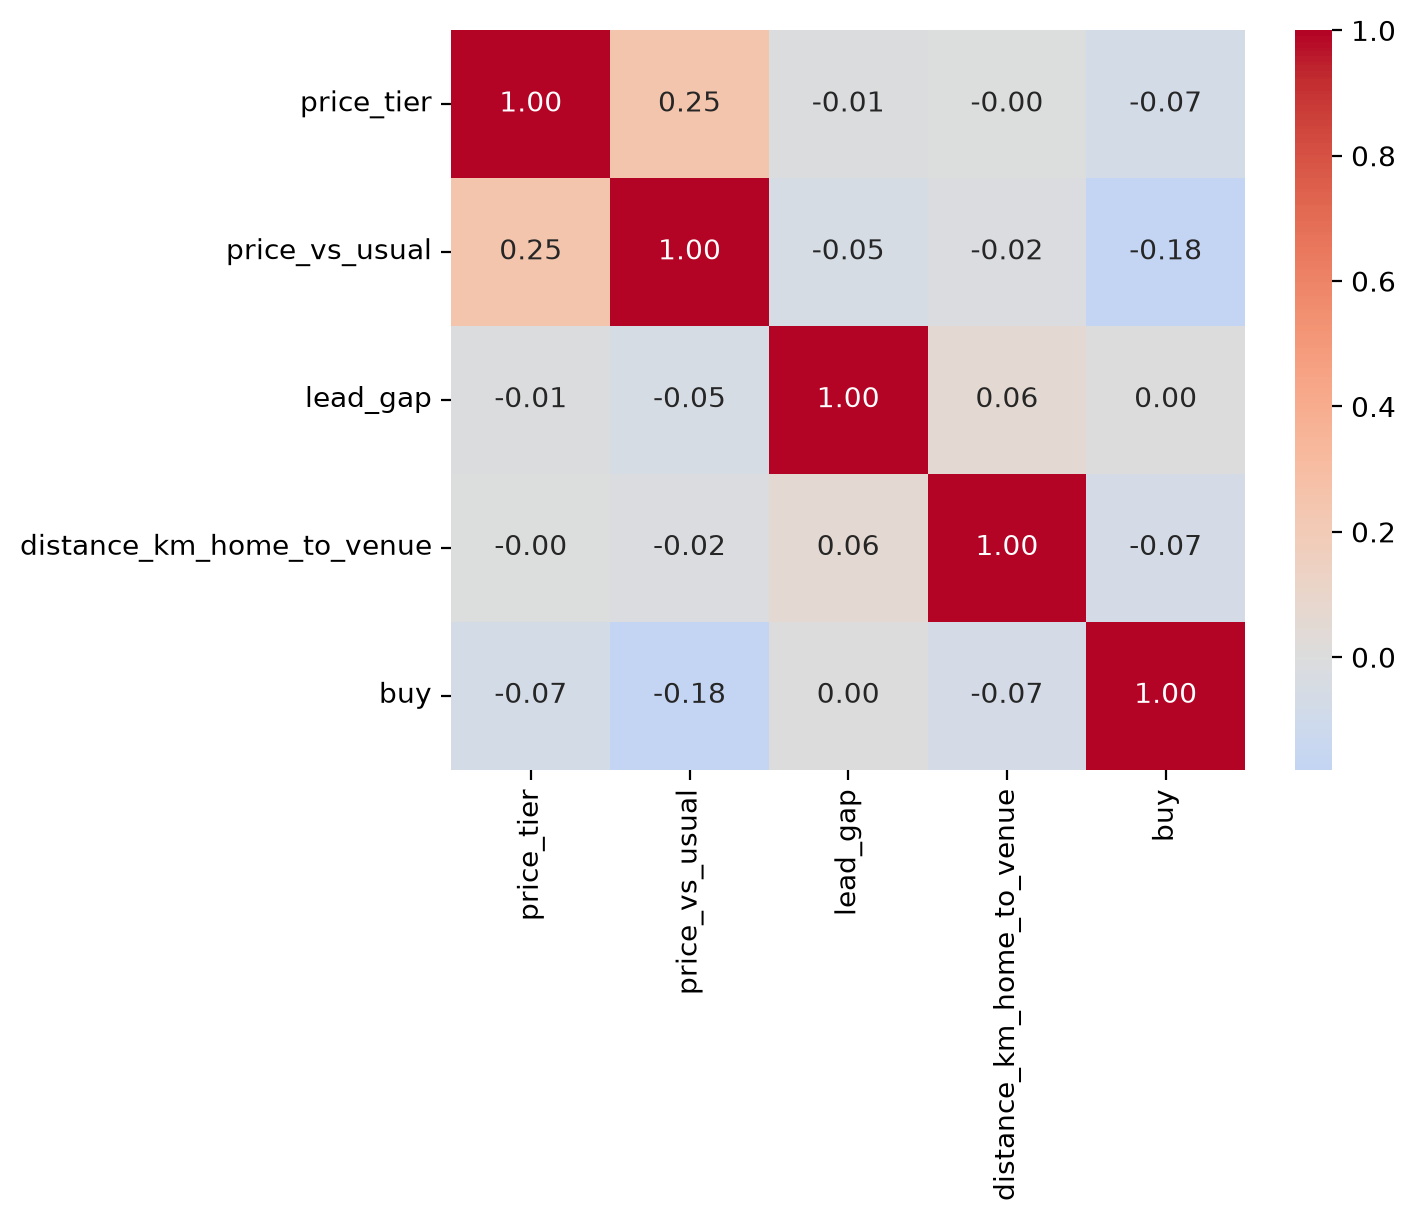

In [13]:
# do the new numeric features go with buying? (spearman, because some are skewed)
new = ["price_tier", "price_vs_usual", "lead_gap", "distance_km_home_to_venue", "buy"]
sb.heatmap(user_concert_train[new].corr(method="spearman"), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.show()

price_tier → buy rate drops from 38.6% (cheapest) to 33.1% to 28.9% (most expensive ticket of its concert): −0.07 with buy.
price_vs_usual → −0.18 with buy: people buy less when the ticket costs more than they usually pay. stronger because first-timers don’t get a made-up median spend. It’s partly related to price_tier (0.25), since both are about price.
distance_km_home_to_venue → −0.07: people further away buy a little less. Weak, because same_city already captures most of it.
lead_gap → 0.00: no straight-line link with buying on its own. I keep it anyway: a correlation only checks one feature at a time, and tree models can still use it in combination with others. The model will decide.

In [14]:
# check: lead_gap is kept, its helper days_to_concert is dropped
print("lead_gap" in user_concert_train.columns, "days_to_concert" in user_concert_train.columns)   # True False

True False


## Categorical features

| Observations (EDA) | Creative idea / feature engineering |
|---|---|
| Home city: weak on its own, but living in the concert's city matters (41% vs 32%) | New feature `same_city`: does the person live in the concert's city? |
| Education: no difference | Nothing to build. Keep it for now and let the model decide |
| Favourite genre: pop highest, metal lowest; fitting the concert matters more (42% vs 30%) | New feature `genre_match`: is their genre one of the concert's genres? |
| Artist: Taylor Swift highest, Tame Impala lowest | Nothing to build. `artist_name` is already the feature |
| Venue city = artist (one city per concert) | Use it to build the features below, then drop it |
| Travel search: only predicts buying when city AND dates match the concert (73% within ±1 day vs about 10% for other dates) | New features `travel_to_venue` (searched this concert's city), `travel_gap_days` (arrival minus concert date) and `travel_date_match` (concert's city + arrives within 1 day) |
| Music app: empty, missing and no-account users buy about 50%, active ones 31% | Already added in the EDA: `music_app_status` |
| Discount: rises with discount | Nothing to build. It's already a number that goes up |
| Wishlisted: 43% vs 32% | Nothing to build. Already a 0/1 flag |
| First timers: 37% vs 32% | Nothing to build. Already a 0/1 flag |

In [15]:
#Feature engineering: categorical 
for df in [user_concert_train, user_concert_test]:
    #1. create same_city,,, 1 if the person lives in the concert's city
    df["same_city"] = (df["home_city"] == df["venue_city"]).astype(int)

    #3. create genre_match,,, if looping through the genres finds a match then assign 1
    df["genre_match"] = [int(g in gs.split("|")) for g, gs in zip(df["stated_favourite_genre"], df["genres"])]

    #6. travel_to_venue: 1 if they searched travel to THIS concert's city
    df["travel_to_venue"] = (df["travel_search_city"] == df["venue_city"]).astype(int)
        
    #7. travel_gap_days: arrival date minus concert date, only for searches to the concert's city                    -------- added extra here... new features for the model found in eda
    gap = (pd.to_datetime(df["travel_search_arrival"]) - pd.to_datetime(df["concert_at"].str[:10])).dt.days
    df["travel_gap_days"] = gap.where(df["travel_to_venue"] == 1)

    #8. travel_date_match: searched the concert's city AND arrives within 1 day of the concert
    df["travel_date_match"] = ((df["travel_to_venue"] == 1) & gap.between(-1, 1)).astype(int)

# checks (train only, since test has no buy column)
print(user_concert_train.groupby("same_city")["buy"].mean())
print(user_concert_train.groupby("genre_match")["buy"].mean())
print(user_concert_train.groupby("travel_to_venue")["buy"].mean())
print(user_concert_train.groupby("travel_date_match")["buy"].mean())

same_city
0    0.322878
1    0.411791
Name: buy, dtype: float64
genre_match
0    0.295247
1    0.424776
Name: buy, dtype: float64
travel_to_venue
0    0.317622
1    0.453724
Name: buy, dtype: float64
travel_date_match
0    0.303765
1    0.732804
Name: buy, dtype: float64


same_city ---> people buy more when the concert is in their own city (41% vs 32%), probably because it’s easier to get to.
genre_match ---> people buy more when the concert matches their favourite genre (42% vs 30%), aka they like the music.
travel_to_venue ---> people who searched for travel to the concert’s city buy more (45% vs 32%), but this mixes two groups: people coming for the concert and people visiting the city on other dates.
travel_date_match ---> people who searched for the concert’s city AND arrive within a day of the concert buy the most (about 73% vs 30%): they’re clearly planning to attend (it’s like a lead). The ones searching other dates buy only about 10%, so the date is what turns a travel search into a real signal. travel_gap_days keeps the exact number of days for the model.

## Music app features (music_app.json)

In [16]:
import json

# ---------- Music app features ----------
# 1. one row per song played
with open("../data/raw/music_app.json") as f:
    plays = pd.json_normalize(json.load(f)["accounts"], record_path=["sessions", "tracks"], meta=["music_app_user_id"])
plays["searched"] = plays["source"] == "search"                                                    # looked it up on purpose
plays["days_ago"] = (pd.Timestamp("2026-10-01", tz="UTC") - pd.to_datetime(plays["played_at"])).dt.days

# 2. per person + artist
artist_listening = plays.groupby(["music_app_user_id", "artist_id"]).agg(
    artist_ms=("played_ms", "sum"),              # time on this artist
    artist_saves=("saved", "sum"),               # songs saved
    artist_searches=("searched", "sum"),         # songs searched for
    artist_days_since_last=("days_ago", "min"),  # how long ago they last played them
).reset_index()
artist_listening["artist_share"] = artist_listening["artist_ms"] / artist_listening.groupby("music_app_user_id")["artist_ms"].transform("sum")

# 3. join onto train and test: 0 for active users who never played the artist, empty for users without listening data
def add_listening(df):
    df = df.merge(artist_listening.drop(columns="artist_ms"), on=["music_app_user_id", "artist_id"], how="left")
    active = df["music_app_status"] == "active"
    cols = ["artist_share", "artist_saves", "artist_searches"]
    df.loc[active, cols] = df.loc[active, cols].fillna(0)
    return df

user_concert_train = add_listening(user_concert_train)
user_concert_test  = add_listening(user_concert_test)

In [17]:
user_concert_train.head(10)

,row_id,user_id,music_app_user_id,age,education,spending_capacity_band,home_city,home_lat,home_lon,stated_favourite_genre,...,distance_km_home_to_venue,same_city,genre_match,travel_to_venue,travel_gap_days,travel_date_match,artist_saves,artist_searches,artist_days_since_last,artist_share
0,R2F019957,U2CFDCAAD,M1B01D2D7,23,postgraduate,2,Nantes,47.218,-1.554,pop,...,507.893880,0,1,0,NaN,0,0.0,0.0,NaN,0.000000
1,R0804D93A,U1FC01010,M1B2C63CC,51,undergraduate,5,Bordeaux,44.838,-0.579,pop,...,436.832882,0,1,0,NaN,0,4.0,6.0,12.0,0.172106
2,R367FE81E,U0C605712,M3AEF638D,32,secondary,1,Lyon,45.764,4.835,classical,...,436.832882,0,0,0,NaN,0,0.0,0.0,67.0,0.005324
3,R344BBE29,U25D1DD8A,M00C580ED,24,secondary,2,Paris,48.857,2.352,jazz_funk,...,0.000000,1,1,0,NaN,0,0.0,1.0,7.0,0.004777
4,R004ABDEB,U1600BC92,M29AC37E6,21,secondary,3,Bordeaux,44.838,-0.579,unknown,...,275.094820,0,0,0,NaN,0,1.0,3.0,1.0,0.076928
5,R366DD8C3,U20C885A7,M28AC108F,44,secondary,3,Paris,48.857,2.352,psychedelic,...,0.000000,1,0,0,NaN,0,NaN,NaN,NaN,NaN
6,R2CEF956D,U2AB90754,M13848379,32,undergraduate,3,Lille,50.630,3.057,rnb_soul,...,0.000000,1,0,0,NaN,0,2.0,4.0,11.0,0.098812
7,R1BFF6A47,U10A9D812,M0CC57650,38,postgraduate,5,Paris,48.857,2.352,classical,...,0.000000,1,0,0,NaN,0,0.0,0.0,NaN,0.000000
8,R2850F394,U1F5D07CE,NaN,57,undergraduate,5,Paris,48.857,2.352,unknown,...,391.733299,0,0,0,NaN,0,NaN,NaN,NaN,NaN
9,R112719F3,U08DFBF05,M1950678C,27,undergraduate,1,Paris,48.857,2.352,pop,...,499.495089,0,1,0,NaN,0,5.0,8.0,1.0,0.273865


In [18]:
user_concert_test.head(10)

,row_id,user_id,music_app_user_id,age,education,spending_capacity_band,home_city,home_lat,home_lon,stated_favourite_genre,...,distance_km_home_to_venue,same_city,genre_match,travel_to_venue,travel_gap_days,travel_date_match,artist_saves,artist_searches,artist_days_since_last,artist_share
0,R3770C503,U3ACC7254,M0DE861B3,46,undergraduate,1,Lyon,45.764,4.835,folk_country,...,0.000000,1,0,1,0.0,1,1.0,2.0,2.0,0.131964
1,R216C3DE0,U1C2E3AFA,M3B7890DA,47,undergraduate,5,Paris,48.857,2.352,rnb_soul,...,391.733299,0,0,0,NaN,0,0.0,2.0,39.0,0.051064
2,R315CFF39,U1593B998,M17CA551F,46,undergraduate,3,Lyon,45.764,4.835,unknown,...,556.935733,0,0,0,NaN,0,0.0,0.0,NaN,0.000000
3,R0CC22A1C,U15FCAF27,M1B1E629F,18,secondary,3,Rennes,48.117,-1.678,classical,...,442.973265,0,0,0,NaN,0,0.0,1.0,64.0,0.002567
4,R30EE7196,U03D69656,M05B8CCEE,63,postgraduate,1,Lyon,45.764,4.835,alternative,...,436.832882,0,1,0,NaN,0,1.0,1.0,15.0,0.086942
5,R16B97FF5,U0F2087E1,M14BA7BEC,53,postgraduate,4,Toulouse,43.604,1.444,classical,...,790.581634,0,0,1,-8.0,0,0.0,0.0,NaN,0.000000
6,R12230F2A,U30CA9BF0,M34B5C96D,26,secondary,3,Lille,50.630,3.057,pop,...,203.639232,0,1,0,NaN,0,0.0,0.0,61.0,0.001000
7,R2876C97C,U2A388E18,M166650D2,63,postgraduate,4,Toulouse,43.604,1.444,unknown,...,465.109535,0,0,0,NaN,0,1.0,4.0,42.0,0.121394
8,R0AC56244,U32319741,M275F416D,58,undergraduate,5,Toulouse,43.604,1.444,classical,...,465.109535,0,0,0,NaN,0,0.0,1.0,72.0,0.001195
9,R09792436,U26DC1C60,M1D8699A7,45,undergraduate,5,Rennes,48.117,-1.678,alternative,...,374.127539,0,1,0,NaN,0,2.0,4.0,13.0,0.085280


In [19]:
# move buy to the last column (train only: test has no buy column)
user_concert_train["buy"] = user_concert_train.pop("buy")

# same columns, same order in test as in train (minus buy)
user_concert_test = user_concert_test[user_concert_train.columns.drop("buy")]
print(list(user_concert_train.columns[-3:]), user_concert_train.shape, user_concert_test.shape)

['artist_days_since_last', 'artist_share', 'buy'] (30000, 47) (20000, 46)


### Check the music app features against buy

music_app_status
active        0.0
empty         1.0
missing       1.0
no_account    1.0
Name: artist_share, dtype: float64


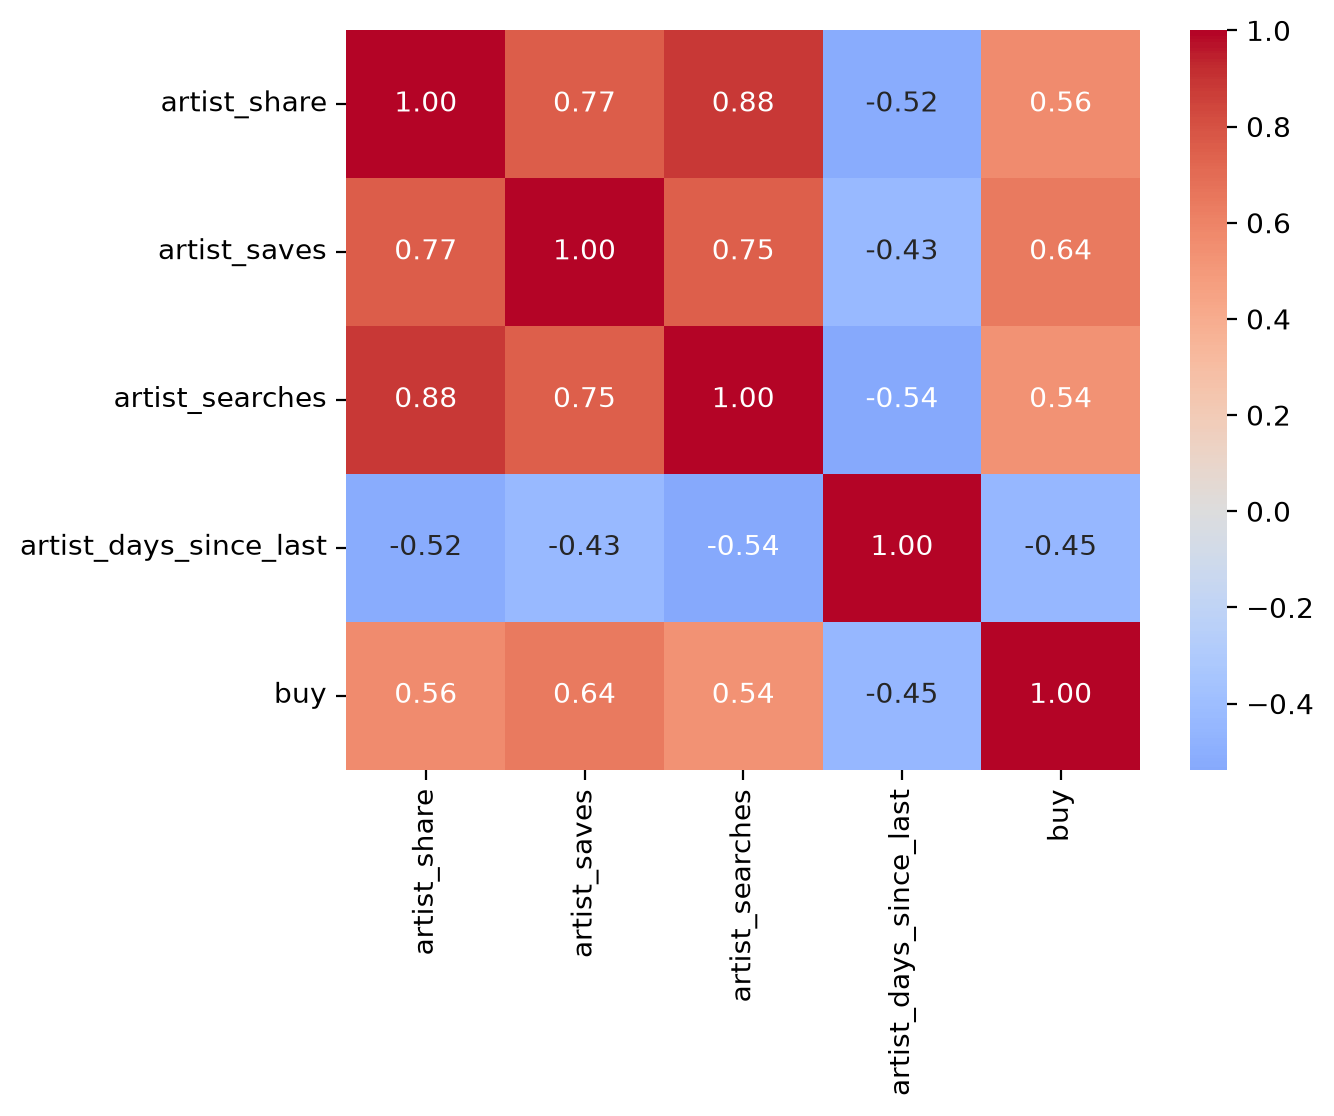

In [20]:
# check 1: music features are filled for active users and empty for everyone else
print(user_concert_train.groupby("music_app_status")["artist_share"].apply(lambda x: x.isna().mean()))

# check 2: do they go with buying?
music_cols = ["artist_share", "artist_saves", "artist_searches", "artist_days_since_last", "buy"]
sb.heatmap(user_concert_train[music_cols].corr(method="spearman"), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.show()

artist_saves ---> 0.64 with buy, the strongest of all my features. People who save an artist’s songs are the most likely to buy a ticket for their concert (basically real fans).
artist_share ---> 0.56: the bigger the share of their listening that goes to the artist, the more they buy.
artist_searches ---> 0.54: searching for the artist on purpose (not autoplay) also goes with buying.
artist_days_since_last ---> −0.45: the longer since they last played the artist, the less they buy, so recent listening matters.

Everything I built before stayed under 0.2 (e.g. price_vs_usual −0.18), so the music app is by far the best source of info. The 4 features overlap a lot (0.75–0.88 with each other) since they all measure “how much of a fan is this person”, which is fine for tree models, they pick what helps most. These numbers only cover active users. For everyone else the features stay empty on purpose, and music_app_status tells the model which case it is.

## Final column drop
Columns that have done their job: IDs used only for joining the music data, concert columns that are one-to-one with artist_name (used to build same_city, genre_match and the travel features), single-value dates, the lat/lon columns replaced by distance_km_home_to_venue, and the raw travel columns replaced by travel_to_venue / travel_gap_days / travel_date_match. row_id and user_id are kept for the submission file and the user-based validation split, but are never used as model inputs.

Not built here: recency features (recent_share, plays_last_14d, trend), found in the EDA. I added them later in 03 modelling as a separate step so I could test whether they help on top of my model + Paul’s 6 (CV F1 0.8406 ---> 0.8455).

In [21]:
cols_to_drop = ["music_app_user_id", "artist_id",                         # only needed to join the music app data
                "concert_id", "concert_at", "venue_city", "genres",       # one per artist (used to build same_city, genre_match, travel features)
                "sale_opened_at", "prediction_at",                        # single value
                "home_lat", "home_lon", "venue_lat", "venue_lon",          # replaced by distance_km_home_to_venue
                "travel_search_city", "travel_search_arrival"]             # replaced by travel_to_venue / travel_gap_days / travel_date_match
user_concert_train = user_concert_train.drop(columns=cols_to_drop)
user_concert_test  = user_concert_test.drop(columns=cols_to_drop)

# moves buy to the end
user_concert_train["buy"] = user_concert_train.pop("buy")
print(user_concert_train.columns.to_list())

['row_id', 'user_id', 'age', 'education', 'spending_capacity_band', 'home_city', 'stated_favourite_genre', 'past_purchase_count', 'first_timer', 'typical_ticket_spend', 'usual_booking_lead_days', 'artist_name', 'ticket_price', 'discount_pct', 'event_page_visits_7d', 'wishlisted', 'music_app_status', 'visits_missing', 'searched_travel', 'price_tier', 'price_vs_usual', 'lead_gap', 'distance_km_home_to_venue', 'same_city', 'genre_match', 'travel_to_venue', 'travel_gap_days', 'travel_date_match', 'artist_saves', 'artist_searches', 'artist_days_since_last', 'artist_share', 'buy']


## Final check and save

artist_days_since_last has more gaps (9147) than the other music features (3820): 3820 users without listening data + active users who never played the artist (no “last play” exists, so it can’t be 0)

In [22]:
# final check: only the intended columns are empty, and train/test match
missing = user_concert_train.isna().sum()
print(missing[missing > 0], "\n")
print("only in train:", set(user_concert_train.columns) - set(user_concert_test.columns))   # should be {'buy'}
print("features:", user_concert_train.shape[1] - 3)   # minus row_id, user_id, buy

# save for the modeling notebook
user_concert_train.to_csv("../data/processed/train_features.csv", index=False)
user_concert_test.to_csv("../data/processed/test_features.csv", index=False)
print(user_concert_train.shape, user_concert_test.shape)

typical_ticket_spend        8240
usual_booking_lead_days     8240
price_vs_usual              8240
lead_gap                    8240
travel_gap_days            25905
artist_saves                3820
artist_searches             3820
artist_days_since_last      9147
artist_share                3820
dtype: int64 

only in train: {'buy'}
features: 30
(30000, 33) (20000, 32)
